# Install dependencies

In [1]:
!pip install -q -U transformers datasets accelerate sentencepiece scikit-learn==1.7.2

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import torch
import transformers
import accelerate
import datasets
import pyarrow
import sklearn

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Datasets:", datasets.__version__)
print("PyArrow:", pyarrow.__version__)
print("Scikit-learn", sklearn.__version__)
print("CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Transformers: 5.22.2
Accelerate: 1.15.0
Datasets: 5.2.0
PyArrow: 26.0.1
Scikit-learn 1.7.2
CUDA: True


# Imports and GPU check

In [3]:
import os
import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from collections import Counter

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

set_seed(42)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


# Locate your prepared JSONL files

In [4]:
INPUT_DIR = Path("/kaggle/input")

train_candidates = list(INPUT_DIR.rglob("train_classifier.jsonl"))
dev_candidates = list(INPUT_DIR.rglob("dev_classifier.jsonl"))

print("Train candidates:", train_candidates)
print("Dev candidates:", dev_candidates)

assert len(train_candidates) == 1, (
    "Expected exactly one train_classifier_v3.jsonl. "
    "Check your Kaggle dataset and filename."
)

assert len(dev_candidates) == 1, (
    "Expected exactly one dev_classifier_v3.jsonl. "
    "Check your Kaggle dataset and filename."
)

TRAIN_PATH = train_candidates[0]
DEV_PATH = dev_candidates[0]

print("\nTrain file:", TRAIN_PATH)
print("Dev file:", DEV_PATH)

Train candidates: [PosixPath('/kaggle/input/datasets/lk1920/fever-data/train_classifier.jsonl')]
Dev candidates: [PosixPath('/kaggle/input/datasets/lk1920/fever-data/dev_classifier.jsonl')]

Train file: /kaggle/input/datasets/lk1920/fever-data/train_classifier.jsonl
Dev file: /kaggle/input/datasets/lk1920/fever-data/dev_classifier.jsonl


# Load and validate the data

In [5]:
label2id = {
    "SUPPORTS": 0,
    "REFUTES": 1,
    "NOT ENOUGH INFO": 2
}

id2label = {v: k for k, v in label2id.items()}

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

train_rows = load_jsonl(TRAIN_PATH)
dev_rows = load_jsonl(DEV_PATH)

print("Train rows:", len(train_rows))
print("Dev rows:", len(dev_rows))

Train rows: 257115
Dev rows: 31391


In [6]:
def normalize_label(label):
    label = label.strip().upper()

    aliases = {
        "SUPPORTS": "SUPPORTS",
        "REFUTES": "REFUTES",
        "NEI": "NOT ENOUGH INFO",
        "NOT ENOUGH INFO": "NOT ENOUGH INFO"
    }

    if label not in aliases:
        raise ValueError(f"Unknown label: {label}")

    return aliases[label]


def prepare_row(row):
    evidence = row["evidence"]

    # Evidence is a list of dictionaries in our prepared dataset.
    evidence_text = " ".join(
        item["text"] if isinstance(item, dict) else str(item)
        for item in evidence
    )

    claim = row["claim"].strip()

    return {
        "claim": claim,
        "evidence": evidence_text,
        "labels": label2id[normalize_label(row["label"])]
    }


train_data = [prepare_row(row) for row in train_rows]
dev_data = [prepare_row(row) for row in dev_rows]

print("Example:")
print(train_data[0])

Example:
{'claim': 'Rafael Nadal was not a professional tennis player', 'evidence': 'Nadal is the only male player in tennis history to win one Grand Slam and at least one Masters 1000 title for ten consecutive years from 2005 -- 2014 .', 'labels': 1}


In [7]:
for split_name, data in [
    ("TRAIN", train_data),
    ("DEV", dev_data)
]:
    label_counts = Counter(x["labels"] for x in data)

    print(f"\n{split_name}")
    print("Rows:", len(data))
    print({
        id2label[k]: v
        for k, v in sorted(label_counts.items())
    })

    empty_claims = sum(not x["claim"] for x in data)
    empty_evidence = sum(not x["evidence"] for x in data)

    print("Empty claims:", empty_claims)
    print("Empty evidence:", empty_evidence)

    assert empty_claims == 0
    assert empty_evidence == 0

# Check original FEVER claim IDs do not cross train/dev.
train_ids = {row["id"] for row in train_rows if "id" in row}
dev_ids = {row["id"] for row in dev_rows if "id" in row}

print("\nClaim ID overlap:", len(train_ids & dev_ids))
assert len(train_ids & dev_ids) == 0


TRAIN
Rows: 257115
{'SUPPORTS': 161249, 'REFUTES': 60227, 'NOT ENOUGH INFO': 35639}
Empty claims: 0
Empty evidence: 0

DEV
Rows: 31391
{'SUPPORTS': 12498, 'REFUTES': 12227, 'NOT ENOUGH INFO': 6666}
Empty claims: 0
Empty evidence: 0

Claim ID overlap: 0


# Subset Data

In [8]:
from sklearn.model_selection import train_test_split

def stratified_subset(data, size, seed=42):
    labels = [x["labels"] for x in data]
    selected, _ = train_test_split(
        data,
        train_size=size,
        random_state=seed,
        stratify=labels
    )
    return selected

small_train_data = stratified_subset(train_data, 10_000)
small_dev_data = stratified_subset(dev_data, 2_000)

train_dataset = Dataset.from_list(small_train_data)
dev_dataset = Dataset.from_list(small_dev_data)

# Load the tokenizer and model

In [9]:
MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id,
    torch_dtype=torch.float32
)

print("Model parameter dtype:", next(model.parameters()).dtype)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Model parameter dtype: torch.float32


# Tokenize claim–evidence pairs

In [10]:
MAX_LENGTH = 192

train_dataset = Dataset.from_list(train_data)
dev_dataset = Dataset.from_list(dev_data)

def tokenize_function(examples):
    return tokenizer(
        examples["claim"],
        examples["evidence"],
        truncation=True,
        max_length=MAX_LENGTH
    )


train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["claim", "evidence"]
)

dev_tokenized = dev_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["claim", "evidence"]
)

print(train_tokenized)
print(dev_tokenized)

Map:   0%|          | 0/257115 [00:00<?, ? examples/s]

Map:   0%|          | 0/31391 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 257115
})
Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 31391
})


In [11]:
sample = train_tokenized[0]

print("Token count:", len(sample["input_ids"]))
print("Label:", id2label[sample["labels"]])
print(tokenizer.decode(sample["input_ids"]))

Token count: 42
Label: REFUTES
[CLS] Rafael Nadal was not a professional tennis player[SEP] Nadal is the only male player in tennis history to win one Grand Slam and at least one Masters 1000 title for ten consecutive years from 2005 -- 2014 .[SEP]


# Define evaluation metrics

In [12]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    }


data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

# Configure training

In [13]:
training_args = TrainingArguments(
    output_dir="/kaggle/working/fever_trial",
    num_train_epochs=1,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=50,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=1,

    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=100,

    fp16=True,
    bf16=False,

    report_to="none",
    dataloader_num_workers=2,
    seed=42
)

In [14]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=dev_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully.")

Trainer initialized successfully.


# Train

In [15]:
train_result = trainer.train()

print("\nTraining completed.")
print(train_result.metrics)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.151663,0.255189,0.972094,0.975067,0.974816,0.974906



Training completed.
{'train_runtime': 6042.3099, 'train_samples_per_second': 42.552, 'train_steps_per_second': 1.33, 'total_flos': 1.925286382592352e+16, 'train_loss': 0.21521724856411661, 'epoch': 1.0}


In [16]:
FINAL_MODEL_DIR = "/kaggle/working/fever-deberta-v3-base"

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Model saved to:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /kaggle/working/fever-deberta-v3-base


# Final evaluation

In [17]:
eval_results = trainer.evaluate()

print("\nDevelopment Results")
for key, value in eval_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
0.151663,0.255189,1,0.972094,0.975067,0.974816,0.974906



Development Results
eval_loss: 0.2552
eval_accuracy: 0.9721
eval_precision_macro: 0.9751
eval_recall_macro: 0.9748
eval_f1_macro: 0.9749


# Classification report and confusion matrix

In [18]:
pred_output = trainer.predict(dev_tokenized)

predictions = np.argmax(pred_output.predictions, axis=-1)
true_labels = pred_output.label_ids

print(classification_report(
    true_labels,
    predictions,
    labels=[0, 1, 2],
    target_names=[
        "SUPPORTS",
        "REFUTES",
        "NOT ENOUGH INFO"
    ],
    digits=4,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


                 precision    recall  f1-score   support

       SUPPORTS     0.9619    0.9762    0.9690     12498
        REFUTES     0.9724    0.9580    0.9652     12227
NOT ENOUGH INFO     0.9908    0.9902    0.9905      6666

       accuracy                         0.9721     31391
      macro avg     0.9751    0.9748    0.9749     31391
   weighted avg     0.9722    0.9721    0.9721     31391



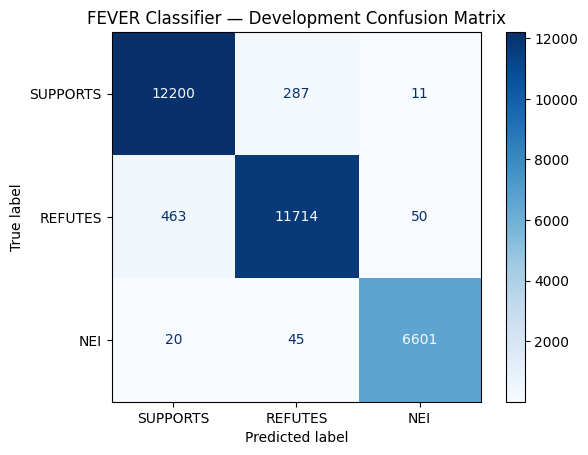

In [19]:
cm = confusion_matrix(
    true_labels,
    predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["SUPPORTS", "REFUTES", "NEI"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("FEVER Classifier — Development Confusion Matrix")
plt.show()

# Inspect misclassified examples

In [20]:
wrong_indices = np.where(predictions != true_labels)[0]

print("Total incorrect predictions:", len(wrong_indices))

for idx in wrong_indices[:15]:
    print("=" * 100)
    print("CLAIM:", dev_data[idx]["claim"])
    print("EVIDENCE:", dev_data[idx]["evidence"])
    print("ACTUAL:", id2label[true_labels[idx]])
    print("PREDICTED:", id2label[predictions[idx]])

    probs = torch.softmax(
        torch.tensor(pred_output.predictions[idx]),
        dim=-1
    ).numpy()

    print("PROBABILITIES:", {
        id2label[i]: round(float(probs[i]), 4)
        for i in range(3)
    })

Total incorrect predictions: 876
CLAIM: Helmand Province is outside of Afghanistan.
EVIDENCE: Helmand -LRB- -LSB- ˈhɛlmənd -RSB- ; Pashto/Dari : هلمند -RRB- , also known as Hillmand , and , in ancient times , as Hermand and Hethumand is one of the 34 provinces of Afghanistan , in the south of the country .
ACTUAL: SUPPORTS
PREDICTED: REFUTES
PROBABILITIES: {'SUPPORTS': 0.0048, 'REFUTES': 0.9952, 'NOT ENOUGH INFO': 0.0001}
CLAIM: Barcelona is the least populated municipality in Spain.
EVIDENCE: Barcelona -LRB- -LSB- bɑrsəˈloʊnə -RSB- , -LSB- bəɾsəˈlonə -RSB- , -LSB- barθeˈlona -RSB- -RRB- is the capital city of the autonomous community of Catalonia in the Kingdom of Spain , as well as the country 's second most populous municipality , with a population of 1.6 million within city limits .
ACTUAL: SUPPORTS
PREDICTED: REFUTES
PROBABILITIES: {'SUPPORTS': 0.0103, 'REFUTES': 0.9896, 'NOT ENOUGH INFO': 0.0001}
CLAIM: Kojol received an award.
EVIDENCE: In 2011 , the Government of India awarded 

# Save a portable model archive

In [21]:
import shutil

shutil.make_archive(
    "/kaggle/working/fever-deberta-v3-base",
    "zip",
    FINAL_MODEL_DIR
)

print("Created model archive.")

Created model archive.


# Extra

In [22]:
import transformers
import accelerate
import inspect

print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

print(inspect.signature(TrainingArguments.__init__))

Transformers: 5.22.2
Accelerate: 1.15.0
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = Non